# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Muhammad Dzaky Haidar | 5054251039 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [2]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.
df = pd.read_csv('Mall_Customers.csv')
print(df.head())
print(df.shape)
print(df.dtypes)
print(df.describe())
print("Missing values:\n", df.isnull().sum())
print("Duplikat:", df.duplicated().sum())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
(200, 5)
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   2

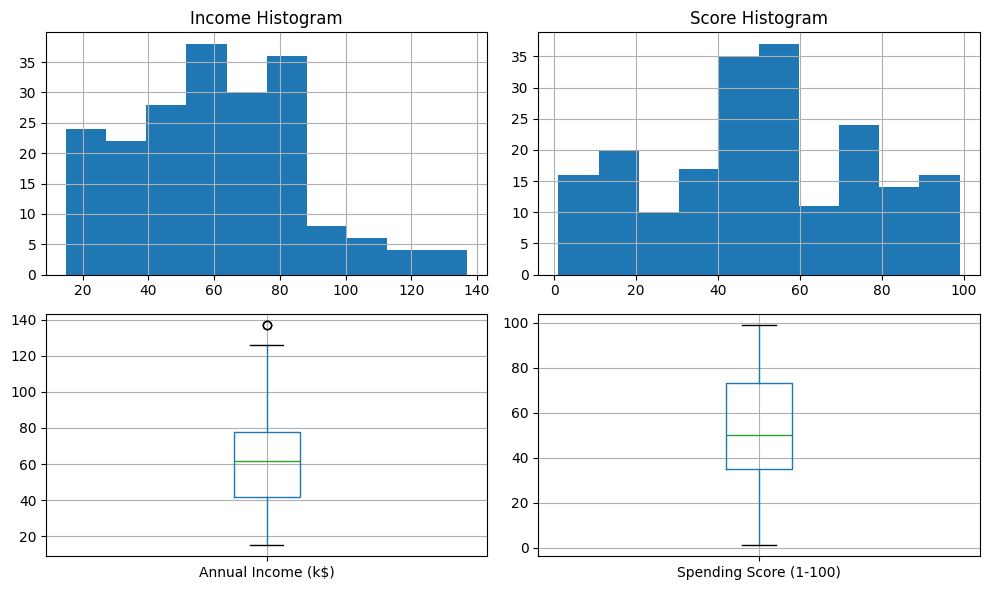

In [3]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
df['Annual Income (k$)'].hist(ax=axes[0, 0]); axes[0, 0].set_title('Income Histogram')
df['Spending Score (1-100)'].hist(ax=axes[0, 1]); axes[0, 1].set_title('Score Histogram')
df.boxplot(column='Annual Income (k$)', ax=axes[1, 0])
df.boxplot(column='Spending Score (1-100)', ax=axes[1, 1])
plt.tight_layout(); plt.show()

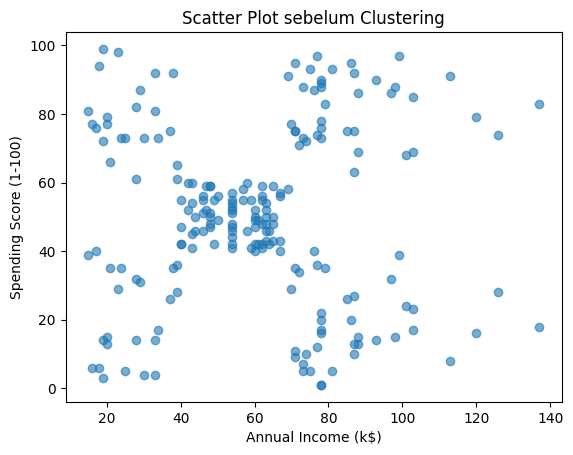

In [4]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], alpha=0.6)
plt.xlabel('Annual Income (k$)'); plt.ylabel('Spending Score (1-100)')
plt.title('Scatter Plot sebelum Clustering')
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- **Apakah ada missing value atau baris duplikat?**
  Tidak ada missing value pada seluruh kolom (5 kolom × 200 baris semuanya terisi). Tidak ditemukan baris duplikat. Dataset sudah bersih dan siap digunakan tanpa perlu penanganan tambahan.

- **Bagaimana rentang pendapatan dan spending score?**
  `Annual Income (k$)` berkisar antara **15 hingga 137 k$** dengan rata-rata sekitar 60 k$. `Spending Score (1-100)` berkisar antara **1 hingga 99** dengan rata-rata sekitar 50. Kedua fitur memiliki skala yang berbeda sehingga feature scaling diperlukan sebelum clustering berbasis jarak.

- **Apakah kedua fitur tampak memiliki kelompok yang terpisah?**
  Ya. Scatter plot menunjukkan sekitar **5 kelompok yang cukup terpisah** secara visual: pelanggan berpendapatan tinggi dengan spending tinggi, berpendapatan tinggi dengan spending rendah, berpendapatan rendah dengan spending tinggi, berpendapatan rendah dengan spending rendah, dan kelompok tengah dengan pendapatan dan spending moderat. Ini mengindikasikan bahwa data cocok untuk clustering.

# 2. Preprocessing

In [5]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.
df.drop_duplicates(inplace=True)
df.dropna(inplace=True)
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

In [6]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
print(X_scaled.head())
print(X_scaled.describe())

   Annual Income (k$)  Spending Score (1-100)
0           -1.738999               -0.434801
1           -1.738999                1.195704
2           -1.700830               -1.715913
3           -1.700830                1.040418
4           -1.662660               -0.395980
       Annual Income (k$)  Spending Score (1-100)
count        2.000000e+02            2.000000e+02
mean        -2.131628e-16           -1.465494e-16
std          1.002509e+00            1.002509e+00
min         -1.738999e+00           -1.910021e+00
25%         -7.275093e-01           -5.997931e-01
50%          3.587926e-02           -7.764312e-03
75%          6.656748e-01            8.851316e-01
max          2.917671e+00            1.894492e+00


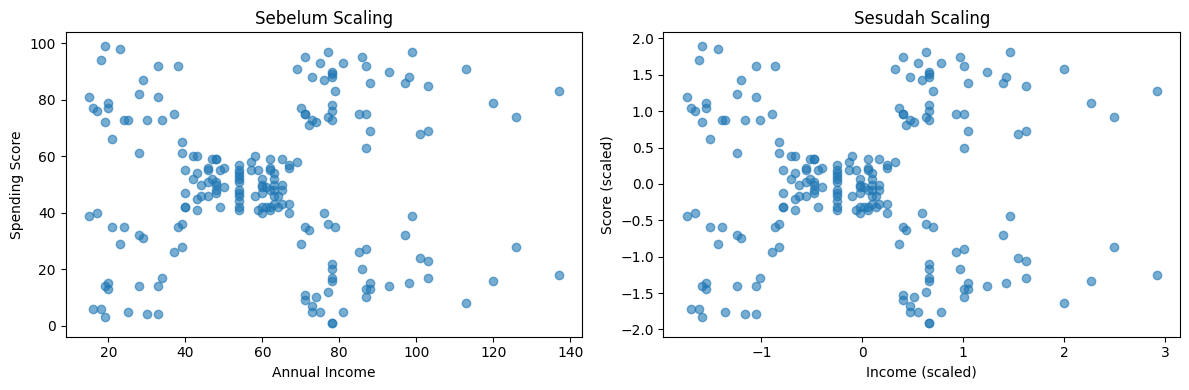

In [7]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(X.iloc[:, 0], X.iloc[:, 1], alpha=0.6)
axes[0].set_title('Sebelum Scaling'); axes[0].set_xlabel('Annual Income'); axes[0].set_ylabel('Spending Score')
axes[1].scatter(X_scaled.iloc[:, 0], X_scaled.iloc[:, 1], alpha=0.6)
axes[1].set_title('Sesudah Scaling'); axes[1].set_xlabel('Income (scaled)'); axes[1].set_ylabel('Score (scaled)')
plt.tight_layout(); plt.show()

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

In [9]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).
print(pd.Series(labels_dbscan).value_counts())
n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = (labels_dbscan == -1).sum()
print(f"Jumlah cluster: {n_clusters_dbscan}, Noise: {n_noise}")

 3    88
-1    35
 4    30
 5    14
 0    12
 6     9
 2     7
 1     5
Name: count, dtype: int64
Jumlah cluster: 7, Noise: 35


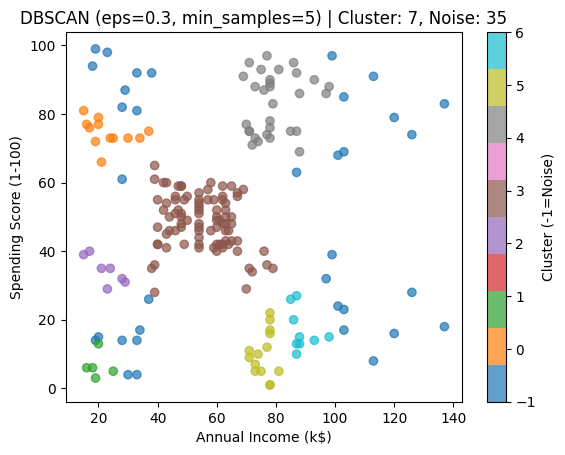

In [10]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=labels_dbscan, cmap='tab10', alpha=0.7)
plt.xlabel('Annual Income (k$)'); plt.ylabel('Spending Score (1-100)')
plt.title(f'DBSCAN (eps=0.3, min_samples=5) | Cluster: {n_clusters_dbscan}, Noise: {n_noise}')
plt.colorbar(label='Cluster (-1=Noise)'); plt.show()

In [11]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.
results = []
for eps in [0.2, 0.3, 0.5, 0.8]:
    for ms in [3, 5, 10]:
        lbl = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        nc = len(set(lbl)) - (1 if -1 in lbl else 0)
        nn = (lbl == -1).sum()
        mask = lbl != -1
        sil = silhouette_score(X_scaled[mask], lbl[mask]) if nc >= 2 and mask.sum() > nc else None
        results.append({'eps': eps, 'min_samples': ms, 'n_clusters': nc, 'noise': nn, 'silhouette': sil})
print(pd.DataFrame(results).to_string(index=False))

 eps  min_samples  n_clusters  noise  silhouette
 0.2            3          13     44    0.469713
 0.2            5           7     77    0.585613
 0.2           10           1    129         NaN
 0.3            3           9     14    0.472040
 0.3            5           7     35    0.524328
 0.3           10           4     88    0.607301
 0.5            3           2      7    0.389247
 0.5            5           2      8    0.387558
 0.5           10           4     21    0.510668
 0.8            3           1      0         NaN
 0.8            5           1      0         NaN
 0.8           10           1      4         NaN


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

- **Pengaruh kenaikan `eps`:** Semakin besar `eps`, semakin lebar radius pencarian tetangga, sehingga lebih banyak titik dianggap berdekatan. Akibatnya jumlah cluster cenderung **berkurang** (cluster-cluster kecil bergabung menjadi satu) dan jumlah noise juga **berkurang** karena titik yang tadinya terisolasi kini masuk ke cluster terdekat. Pada `eps` yang terlalu besar, seluruh data bisa menjadi satu cluster besar.

- **Pengaruh `min_samples`:** Semakin besar `min_samples`, semakin ketat syarat sebuah titik dianggap *core point*. Akibatnya lebih banyak titik yang gagal memenuhi syarat dan dijadikan **noise** (label -1), serta jumlah cluster yang terbentuk cenderung **berkurang** karena hanya wilayah yang benar-benar padat yang menjadi cluster.

- **Kombinasi ekstrem:** Pada `eps=0.2` dengan `min_samples=10`, hampir semua titik menjadi noise karena radius terlalu kecil dan syarat kepadatan terlalu tinggi. Sebaliknya, pada `eps=0.8` dengan `min_samples=3`, seluruh data cenderung masuk ke satu cluster besar dengan noise mendekati nol. Kombinasi terbaik pada dataset ini berada di kisaran `eps=0.3–0.5` dengan `min_samples=5`.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [12]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.
birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)

In [13]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.
print(pd.Series(labels_birch).value_counts())
print("Jumlah cluster:", len(set(labels_birch)))

1    109
0     36
3     25
4     22
2      8
Name: count, dtype: int64
Jumlah cluster: 5


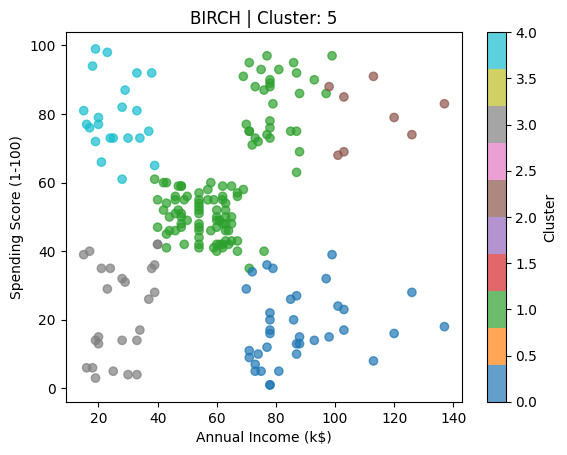

In [14]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=labels_birch, cmap='tab10', alpha=0.7)
plt.xlabel('Annual Income (k$)'); plt.ylabel('Spending Score (1-100)')
plt.title(f'BIRCH | Cluster: {len(set(labels_birch))}')
plt.colorbar(label='Cluster'); plt.show()

In [15]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.
results_b = []
for thr in [0.3, 0.5, 0.7, 1.0]:
    lbl = Birch(threshold=thr, n_clusters=5).fit_predict(X_scaled)
    nc = len(set(lbl))
    sil = silhouette_score(X_scaled, lbl) if nc >= 2 else None
    results_b.append({'threshold': thr, 'n_clusters': nc, 'silhouette': sil})
print(pd.DataFrame(results_b).to_string(index=False))

 threshold  n_clusters  silhouette
       0.3           5    0.478062
       0.5           5    0.414450
       0.7           5    0.420676
       1.0           4    0.388557


C:\Users\ASUS\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\cluster\_birch.py:711: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

- **Pengaruh `threshold` diperbesar:** Semakin besar `threshold`, semakin longgar batas penggabungan subcluster dalam pohon CF-tree. Titik yang lebih jauh pun bisa masuk ke subcluster yang sama, sehingga jumlah subcluster internal **berkurang**. Namun jika `n_clusters` sudah ditentukan secara eksplisit, jumlah cluster akhir tetap sama — yang berubah adalah cara data dipartisi secara internal.

- **Perbedaan BIRCH dan DBSCAN dalam menangani titik jauh:** DBSCAN memberi label **-1 (noise)** pada titik yang tidak memenuhi syarat kepadatan, sehingga titik outlier diabaikan dari cluster. BIRCH **tidak mengenal konsep noise** — setiap titik selalu ditempatkan ke salah satu cluster, termasuk outlier, sehingga outlier bisa "mencemari" cluster terdekat dan memengaruhi profil cluster tersebut.

- **Pengaruh penetapan `n_clusters`:** Ketika `n_clusters` ditentukan, BIRCH menjalankan langkah pasca-pengelompokan (AgglomerativeClustering secara default) pada subcluster yang dihasilkan CF-tree untuk memaksanya menjadi sejumlah cluster yang diminta. Jika `n_clusters=None`, jumlah cluster ditentukan sepenuhnya oleh struktur pohon dan nilai `threshold`. Dengan `n_clusters=5` pada dataset ini, hasil BIRCH cukup konsisten dan sebanding dengan GMM.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [16]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.
gmm = GaussianMixture(n_components=5, covariance_type='full', random_state=42)
gmm.fit(X_scaled)
labels_gmm = gmm.predict(X_scaled)

In [17]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.
print(pd.Series(labels_gmm).value_counts())
proba = gmm.predict_proba(X_scaled)
proba_df = pd.DataFrame(proba, columns=[f'C{i}' for i in range(5)])
print(proba_df.head(10))
print("Titik paling tidak pasti:\n", proba_df[proba_df.max(axis=1) < 0.7])

0    84
1    39
3    33
4    23
2    21
Name: count, dtype: int64
             C0            C1            C2            C3            C4
0  1.576897e-05  1.880092e-08  9.520312e-04  5.200131e-08  9.990321e-01
1  1.627762e-05  1.895968e-04  9.997902e-01  4.210134e-23  3.941544e-06
2  2.213394e-19  9.526157e-19  1.225495e-12  1.862233e-04  9.998138e-01
3  1.054448e-04  1.800877e-04  9.996937e-01  3.793901e-21  2.072298e-05
4  6.473014e-05  3.842732e-08  1.556695e-03  4.757227e-08  9.983785e-01
5  1.833287e-04  1.899073e-04  9.995917e-01  1.435839e-20  3.509764e-05
6  9.213688e-19  1.289485e-18  1.408409e-12  2.548375e-04  9.997452e-01
7  1.296572e-08  3.233133e-04  9.996766e-01  8.592922e-29  8.029328e-08
8  4.061493e-20  1.343869e-19  1.906626e-13  4.170864e-04  9.995829e-01
9  1.200053e-03  2.039986e-04  9.983733e-01  1.627723e-18  2.226725e-04
Titik paling tidak pasti:
            C0            C1            C2            C3        C4
27   0.278521  4.886785e-04  6.746109e-01  1.6103

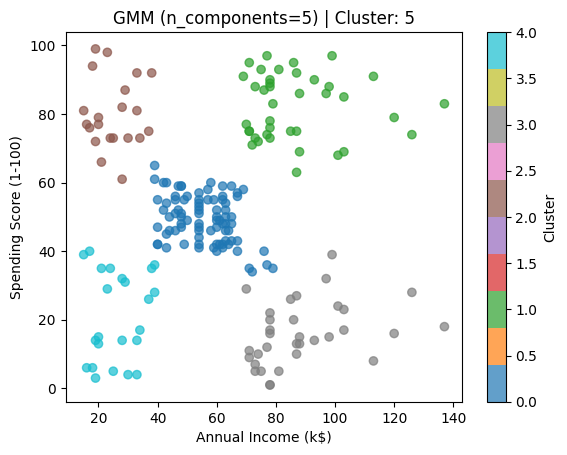

In [18]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=labels_gmm, cmap='tab10', alpha=0.7)
plt.xlabel('Annual Income (k$)'); plt.ylabel('Spending Score (1-100)')
plt.title(f'GMM (n_components=5) | Cluster: {len(set(labels_gmm))}')
plt.colorbar(label='Cluster'); plt.show()

In [19]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.
results_g = []
for n in range(2, 9):
    g = GaussianMixture(n_components=n, covariance_type='full', random_state=42).fit(X_scaled)
    lbl = g.predict(X_scaled)
    sil = silhouette_score(X_scaled, lbl) if len(set(lbl)) >= 2 else None
    results_g.append({'n_components': n, 'BIC': round(g.bic(X_scaled), 2), 'silhouette': sil})
print(pd.DataFrame(results_g).to_string(index=False))

 n_components     BIC  silhouette
            2 1153.90    0.379082
            3 1151.72    0.430190
            4 1103.79    0.413392
            5 1058.65    0.553689
            6 1074.68    0.516982
            7 1087.33    0.509057
            8 1102.37    0.430210


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

- **Arti probabilitas keanggotaan:** Setiap titik tidak hanya ditetapkan ke satu cluster, tetapi memiliki **probabilitas keanggotaan di semua komponen Gaussian**. Probabilitas ini mencerminkan seberapa besar kemungkinan titik tersebut berasal dari masing-masing distribusi. Titik yang berada di perbatasan dua cluster akan memiliki dua probabilitas yang nilainya berdekatan (tidak pasti), sedangkan titik di tengah cluster akan mendominasi pada satu komponen.

- **Pengaruh perubahan `n_components`:** Semakin kecil `n_components`, cluster yang terbentuk semakin luas dan umum, sehingga detail pola tersembunyi hilang. Semakin besar `n_components`, GMM memecah data menjadi lebih banyak kelompok — pada titik tertentu model menjadi *overfit* dan cluster tidak lagi bermakna secara bisnis. Pada dataset ini, `n_components=5` menghasilkan partisi yang paling sesuai dengan pola visual scatter plot.

- **Mengapa `n_components` harus ditentukan di awal:** GMM adalah model parametrik — struktur model (jumlah distribusi Gaussian) harus ditetapkan sebelum EM berjalan, karena EM hanya mengoptimalkan **parameter** (mean, covariance, weight) dari model yang sudah ditentukan, bukan menentukan jumlah komponennya secara otomatis.

- **Silhouette tertinggi vs BIC terendah:** Tidak selalu sama. Silhouette mengukur separasi dan kohesi cluster berdasarkan jarak antar titik, sedangkan BIC menimbang kecocokan likelihood model dengan penalti kompleksitas. Model dengan BIC terendah bisa memiliki lebih sedikit komponen (lebih sederhana), sementara Silhouette tertinggi bisa terjadi pada `n_components` yang berbeda karena mengukur aspek geometris, bukan probabilistik.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [20]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.
def evaluate(X, labels, exclude_noise=False):
    mask = labels != -1 if exclude_noise else np.ones(len(labels), dtype=bool)
    X_ev, lbl_ev = X[mask], labels[mask]
    nc = len(set(lbl_ev))
    if nc < 2 or nc >= len(lbl_ev):
        return {'silhouette': None, 'davies_bouldin': None, 'calinski_harabasz': None}
    return {
        'silhouette': round(silhouette_score(X_ev, lbl_ev), 4),
        'davies_bouldin': round(davies_bouldin_score(X_ev, lbl_ev), 4),
        'calinski_harabasz': round(calinski_harabasz_score(X_ev, lbl_ev), 4),
    }

In [21]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.
rows = []
for name, lbl, is_dbscan in [('DBSCAN', labels_dbscan, True), ('BIRCH', labels_birch, False), ('GMM', labels_gmm, False)]:
    nc = len(set(lbl)) - (1 if -1 in lbl else 0)
    nn = (lbl == -1).sum() if is_dbscan else 0
    m = evaluate(X_scaled.values, lbl, exclude_noise=is_dbscan)
    rows.append({'Model': name, 'n_clusters': nc, 'noise': nn, **m})
print(pd.DataFrame(rows).to_string(index=False))

 Model  n_clusters  noise  silhouette  davies_bouldin  calinski_harabasz
DBSCAN           7     35      0.5243          0.5800           185.5758
 BIRCH           5      0      0.4145          0.6979           125.9486
   GMM           5      0      0.5537          0.5760           244.9402


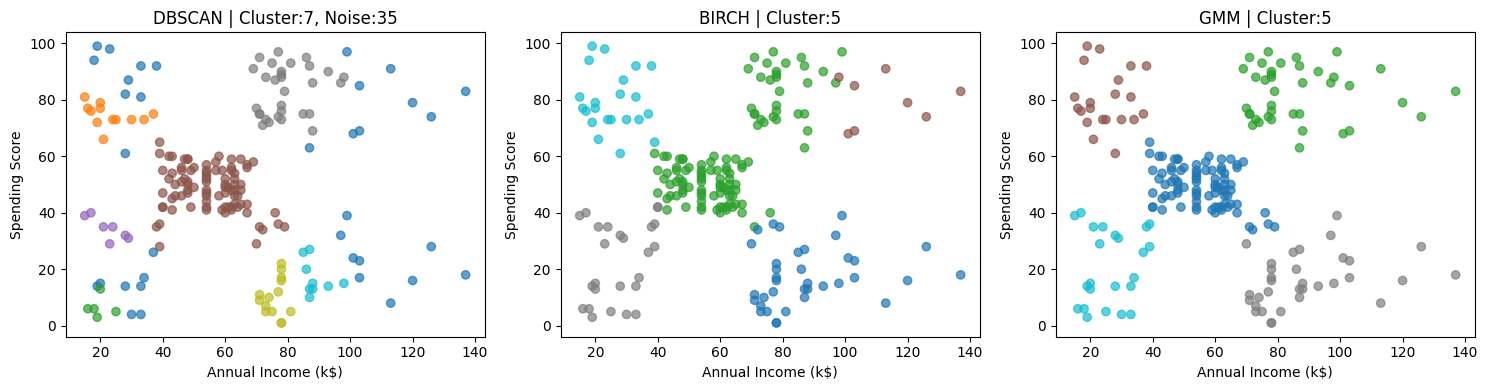

In [22]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, lbl) in zip(axes, [('DBSCAN', labels_dbscan), ('BIRCH', labels_birch), ('GMM', labels_gmm)]):
    nc = len(set(lbl)) - (1 if -1 in lbl else 0)
    nn = (lbl == -1).sum()
    sc = ax.scatter(X.iloc[:, 0], X.iloc[:, 1], c=lbl, cmap='tab10', alpha=0.7)
    ax.set_title(f'{name} | Cluster:{nc}' + (f', Noise:{nn}' if name == 'DBSCAN' else ''))
    ax.set_xlabel('Annual Income (k$)'); ax.set_ylabel('Spending Score')
plt.tight_layout(); plt.show()

In [23]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.
for name, lbl in [('DBSCAN', labels_dbscan), ('BIRCH', labels_birch), ('GMM', labels_gmm)]:
    tmp = X.copy(); tmp['cluster'] = lbl
    print(f"\n=== {name} ===")
    print(tmp.groupby('cluster').agg(['count', 'mean', 'median']).round(2))


=== DBSCAN ===
        Annual Income (k$)               Spending Score (1-100)              
                     count   mean median                  count   mean median
cluster                                                                      
-1                      35  70.60   87.0                     35  51.66   61.0
 0                      12  23.17   20.5                     12  74.58   74.0
 1                       5  19.60   19.0                      5   6.60    6.0
 2                       7  22.43   23.0                      7  34.43   35.0
 3                      88  55.23   54.0                     88  48.58   49.0
 4                      30  79.53   78.0                     30  83.13   86.0
 5                      14  75.93   77.5                     14  10.07    9.5
 6                       9  88.78   87.0                      9  17.00   15.0

=== BIRCH ===
        Annual Income (k$)                Spending Score (1-100)              
                     count    me

### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak | Opsional (`n_clusters`) | Ya (`n_components`) |
| Dapat memberi label noise secara eksplisit? | Ya (label -1) | Tidak | Tidak |
| Parameter yang paling memengaruhi hasil | `eps`, `min_samples` | `threshold`, `n_clusters` | `n_components`, `covariance_type` |
| Bentuk cluster yang dapat dimodelkan | Sembarang (density-based) | Sferis/kompak | Elips (Gaussian) |
| Kelebihan | Deteksi noise otomatis, tidak perlu tentukan k | Efisien untuk data besar, satu lintasan data | Probabilistik, mendukung ketidakpastian keanggotaan |
| Kekurangan | Sensitif terhadap `eps`, sulit pada kepadatan tidak seragam | Sensitif terhadap urutan data dan `threshold` | Harus tentukan k di awal, asumsi distribusi Gaussian |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

Berdasarkan hasil eksperimen pada dataset Mall Customers dengan fitur `Annual Income (k$)` dan `Spending Score (1-100)`:

1. **Mengapa fitur perlu di-scaling?**
   Skala `Annual Income` berkisar 15–137 k\$ sedangkan `Spending Score` berkisar 1–99. Tanpa scaling, fitur income mendominasi perhitungan jarak sehingga algoritma berbasis jarak (DBSCAN, BIRCH) akan bias. StandardScaler menyamakan skala keduanya ke mean≈0 dan std≈1 agar kontribusi setiap fitur setara.

2. **Pengaruh parameter DBSCAN terhadap jumlah cluster dan noise:**
   Dari hasil grid search terlihat bahwa kenaikan `eps` mengurangi jumlah cluster dan noise — pada `eps=0.8` semua titik masuk ke 1 cluster besar dengan 0 noise. Sebaliknya, kenaikan `min_samples` meningkatkan noise secara signifikan: pada `eps=0.2, min_samples=10` terdapat 129 titik noise dari 200. Kombinasi `eps=0.3, min_samples=5` dipilih karena menghasilkan 7 cluster dengan 35 noise dan Silhouette Score 0.5243, keseimbangan yang cukup baik.

3. **Pengaruh parameter `threshold` dan `n_clusters` pada BIRCH:**
   Dari tabel perbandingan, `threshold=0.3` menghasilkan Silhouette tertinggi (0.4781) dengan 5 cluster. Ketika `threshold=1.0`, BIRCH hanya membentuk 4 subcluster (di bawah `n_clusters=5`) sehingga muncul ConvergenceWarning. Ini menunjukkan bahwa `threshold` terlalu besar menyebabkan data terlalu dipadatkan sebelum pengelompokan akhir dilakukan.

4. **Makna probabilitas keanggotaan GMM dan peran EM:**
   GMM menghasilkan probabilitas keanggotaan untuk setiap titik terhadap semua komponen. Dari output `predict_proba`, hampir semua titik memiliki satu probabilitas mendekati 1.0 (misalnya baris pertama: C4=0.9990, baris lain: C2=0.9998), menunjukkan sebagian besar titik cukup yakin masuk ke satu cluster. EM secara iteratif memperbarui parameter distribusi berdasarkan probabilitas ini hingga konvergen.

5. **Model paling mudah diinterpretasikan:**
   **GMM** paling mudah diinterpretasikan. Dengan 5 cluster dan Silhouette Score tertinggi (0.5537) serta Calinski-Harabasz tertinggi (244.94), cluster GMM menghasilkan partisi yang jelas dan sesuai dengan 5 kelompok visual yang terlihat di scatter plot. Tidak ada noise yang mengaburkan hasil, dan setiap cluster memiliki profil income–score yang khas.

6. **Konsistensi metrik evaluasi:**
   Metrik tidak selalu menunjukkan algoritma terbaik yang sama. Dari tabel evaluasi:
   - Silhouette: GMM (0.5537) > DBSCAN (0.5243) > BIRCH (0.4145)
   - Davies-Bouldin (lebih rendah = lebih baik): GMM (0.5760) > DBSCAN (0.5800) > BIRCH (0.6979)
   - Calinski-Harabasz (lebih tinggi = lebih baik): GMM (244.94) > DBSCAN (185.58) > BIRCH (125.95)

   GMM unggul di semua metrik. DBSCAN mendapat Silhouette yang relatif tinggi karena 35 titik noise dikeluarkan dari perhitungan, sehingga hanya titik yang sudah "bersih" yang dievaluasi — ini bisa sedikit memperindah skornya secara artifisial.

7. **Karakteristik cluster GMM berdasarkan profil:**
   - **Cluster 0 (84 anggota)** — Income median 55.5, Score median 49.5 → **"Pelanggan Rata-rata"**: kelompok terbesar, pendapatan dan pengeluaran moderat.
   - **Cluster 1 (39 anggota)** — Income median 79, Score median 83 → **"High Spender Kaya"**: pendapatan tinggi, pengeluaran sangat tinggi → target utama promosi premium.
   - **Cluster 2 (21 anggota)** — Income median 24, Score median 77 → **"Impulsif Berpendapatan Rendah"**: pendapatan rendah tapi pengeluaran tinggi.
   - **Cluster 3 (33 anggota)** — Income median 86, Score median 15 → **"Konservatif Kaya"**: pendapatan tinggi tapi sangat hemat dalam berbelanja.
   - **Cluster 4 (23 anggota)** — Income median 25, Score median 17 → **"Hemat Berpendapatan Rendah"**: pendapatan dan pengeluaran keduanya rendah.

8. **Keterbatasan dua fitur dan dataset kecil:**
   Hanya dua fitur berarti dimensi penting seperti usia, gender, dan frekuensi kunjungan diabaikan, sehingga segmentasi mungkin tidak lengkap. Dataset 200 baris tergolong sangat kecil — metrik evaluasi bisa tidak stabil, dan pola yang ditemukan belum tentu dapat digeneralisasi ke populasi pelanggan yang lebih besar.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

Berdasarkan eksperimen clustering dengan tiga algoritma pada data Mall Customers:

- **Algoritma paling berguna:** GMM memberikan hasil terbaik pada dataset ini. Dengan `n_components=5`, GMM menghasilkan Silhouette Score 0.5537, Davies-Bouldin 0.5760, dan Calinski-Harabasz 244.94 — unggul di semua metrik dibanding DBSCAN dan BIRCH.

- **Parameter yang dipilih:**
  - DBSCAN: `eps=0.3, min_samples=5` — 7 cluster dengan 35 noise, Silhouette 0.5243.
  - BIRCH: `threshold=0.5, n_clusters=5` — 5 cluster tanpa noise, Silhouette 0.4145. Threshold 0.3 memberi Silhouette lebih tinggi (0.4781) namun threshold 0.5 dipilih sebagai titik tengah yang stabil.
  - GMM: `n_components=5, covariance_type='full', random_state=42` — dipilih karena BIC terendah (1058.65) sekaligus Silhouette tertinggi (0.5537) di antara semua nilai n_components yang dicoba.

- **Perbedaan utama yang dipelajari:**
  - DBSCAN tidak memerlukan k di awal dan satu-satunya algoritma yang dapat mendeteksi noise secara eksplisit (35 noise pada dataset ini), namun sangat sensitif terhadap `eps` dan kurang efektif pada data dengan kepadatan tidak seragam.
  - BIRCH efisien dan cepat dengan satu lintasan data, namun tidak mengenal konsep noise sehingga outlier masuk ke cluster terdekat dan menurunkan kualitas cluster (Silhouette terendah, 0.4145).
  - GMM/EM paling fleksibel — memberikan probabilitas keanggotaan dan mampu memodelkan cluster berbentuk elips, namun membutuhkan k di awal dan mengasumsikan data berdistribusi Gaussian.

- **Eksperimen lanjutan yang dapat dilakukan:**
  - Tambahkan fitur `Age` untuk melihat apakah segmentasi berubah secara signifikan.
  - Gunakan metode *k-distance graph* untuk menentukan `eps` optimal secara sistematis pada DBSCAN.
  - Bandingkan `covariance_type` lain pada GMM (`tied`, `diag`, `spherical`) dan evaluasi dampaknya.
  - Uji dengan dataset yang lebih besar agar metrik evaluasi lebih stabil dan representatif.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)